# Etapa 4: Random Tree

Entrada: as mesmas linhas completas de `data/processed/chembl_4targets.csv` usadas no notebook 03, com os 17 atributos e a divisão agrupada.

A Random Tree é uma árvore de decisão que, em cada nó, sorteia K atributos e escolhe a melhor pergunta só entre eles. No scikit-learn, é o `DecisionTreeClassifier` com `max_features=K`.



## 0. Configuração
Célula 1. Preparação

In [6]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

from src import modeling
from src.config import FINAL_CSV, FEATURE_SETS

final = pd.read_csv(FINAL_CSV)
dados = modeling.prepare(final)

## 1. Treino e teste

Mesma divisão agrupada do notebook 03: moléculas com descritores idênticos nunca ficam em lados opostos.
Célula 2. Separar treino e teste


In [7]:
atributos = FEATURE_SETS["descritores + SMILES"]
treino, teste = dados.splits["agrupada"]

X_treino = dados.X[atributos].iloc[treino]
X_teste = dados.X[atributos].iloc[teste]
y_treino = dados.y.iloc[treino]
y_teste = dados.y.iloc[teste]

print(X_treino.shape, X_teste.shape)

(21980, 17) (5496, 17)


## 2. Árvore de decisão × Random Tree

As duas usam os hiperparâmetros escolhidos no notebook 03 (entropia, sem limite de profundidade, sem poda). A única diferença é `max_features`: a árvore testa os 17 atributos em cada nó, e a Random Tree sorteia 5. Célula 3. Uma função que treina e resume a árvore. Célula 4. Treinar as duas e comparar.


In [8]:
def avaliar(modelo):
    modelo.fit(X_treino, y_treino)
    return {
        "acurácia treino": accuracy_score(y_treino, modelo.predict(X_treino)),
        "acurácia teste": accuracy_score(y_teste, modelo.predict(X_teste)),
        "folhas": modelo.get_n_leaves(),
        "profundidade": modelo.get_depth(),
        "atributo da raiz": atributos[modelo.tree_.feature[0]],
        "limiar da raiz": modelo.tree_.threshold[0],
    }

In [9]:
arvore = DecisionTreeClassifier(criterion="entropy", random_state=42)
random_tree = DecisionTreeClassifier(criterion="entropy", max_features=5, random_state=42)

resultados = pd.DataFrame({
    "Árvore de decisão": avaliar(arvore),
    "Random Tree (K=5)": avaliar(random_tree),
})
resultados

,Árvore de decisão,Random Tree (K=5)
acurácia treino,1.0,1.0
acurácia teste,0.896652,0.88246
folhas,1854,2559
profundidade,24,23
atributo da raiz,TPSA,HBD
limiar da raiz,67.895,1.5


**Resultado.** A árvore de decisão reproduz o notebook 03 (0,897; 1.854 folhas; raiz TPSA ≤ 67,9). A Random Tree com K=5 acerta 0,882 no teste, 1,4 ponto a menos, e precisa de 38% mais folhas (2.559), porque, sem o melhor atributo em todos os nós, cada pergunta separa as classes um pouco pior. A profundidade quase não muda (23 contra 24).

A raiz passou a ser HBD ≤ 1,5: a TPSA não foi sorteada (chance de 5 em 17), e a árvore usou um atributo correlacionado, que também mede polaridade. Este é um resultado de uma semente só; a variação entre sementes é medida no experimento 3.

## 3. Qual é o melhor K?

Acurácia de treino e de validação cruzada (5 partes agrupadas, dentro do treino) para K = 1, 2, 3, 5, 8, 12 e 17. K = 17 é a árvore de decisão. O conjunto de teste não é usado nesta escolha.

Célula de código: a curva.

In [10]:
from sklearn.model_selection import StratifiedGroupKFold, validation_curve
from src.config import CV_FOLDS

valores_k = [1, 2, 3, 5, 8, 12, 17]
grupos_treino = dados.grupos[treino]
cv = StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=42)

acc_treino, acc_validacao = validation_curve(
    DecisionTreeClassifier(criterion="entropy", random_state=42),
    X_treino, y_treino,
    param_name="max_features", param_range=valores_k,
    groups=grupos_treino, cv=cv, n_jobs=-1,
)

curva_k = pd.DataFrame({
    "K": valores_k,
    "treino": acc_treino.mean(axis=1),
    "validação": acc_validacao.mean(axis=1),
    "desvio validação": acc_validacao.std(axis=1),
})
curva_k

,K,treino,validação,desvio validação
0,1,1.0,0.797771,0.006596
1,2,1.0,0.836715,0.008119
2,3,1.0,0.858053,0.008014
3,5,1.0,0.870928,0.010323
4,8,1.0,0.874340,0.007257
5,12,1.0,0.872384,0.010540
6,17,1.0,0.878344,0.005134


Célula de código: o gráfico

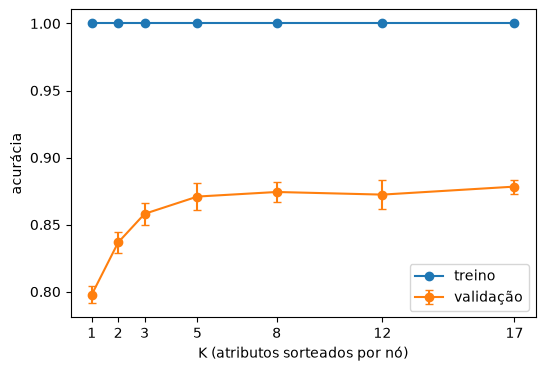

In [11]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(curva_k["K"], curva_k["treino"], marker="o", label="treino")
ax.errorbar(curva_k["K"], curva_k["validação"], yerr=curva_k["desvio validação"],
            marker="o", capsize=3, label="validação")
ax.set_xlabel("K (atributos sorteados por nó)")
ax.set_ylabel("acurácia")
ax.set_xticks(valores_k)
ax.legend()
plt.show()

**Resultado.** A acurácia de treino é 100% para todo K: sem limite de profundidade, a árvore divide até as folhas ficarem puras. A validação sobe rápido de K=1 (0,798) a K=5 (0,871) e forma um platô: de K=5 a K=17 (0,878, igual ao notebook 03) as diferenças são menores que 1 ponto, do tamanho do desvio entre as partes da validação cruzada.

Para uma árvore sozinha, sortear atributos não melhora a acurácia; no máximo empata. A partir de K=5 a aleatoriedade custa menos de 1 ponto. Os próximos experimentos usam K=5.
